# Tech Challenge — Fase 2 | Análise Exploratória de Dados (EDA)

**Projeto:** Classificação binária da qualidade de vinhos — FIAP Pós-Tech Data Analytics  
**Base única:** `WineQT.csv`, fornecida no conjunto Wine Quality indicado pelo enunciado.  
**Meta:** compreender distribuições, correlações, possíveis outliers/inconsistências e o balanceamento das classes.  
**Regra da variável-alvo:** alta qualidade = 1 (nota ≥ 7); baixa/média = 0 (nota < 7).

> Notebook exploratório: preserva o arquivo original e documenta observações estatísticas, sem remover registros ou antecipar decisões da modelagem. Gráficos são salvos em `results/figures/`.

## Preparação do ambiente e leitura do arquivo

Execute **Kernel → Restart & Run All** com a pasta do projeto aberta no VS Code. O diretório de execução deve ser a raiz do repositório ou sua pasta `notebooks/`.

In [1]:

import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("Ambiente configurado com sucesso!")


Python: 3.14.7
Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1
Ambiente configurado com sucesso!


In [2]:

from pathlib import Path
import pandas as pd

# Identificar a pasta principal do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Localizar o dataset original
arquivo = raiz / "data" / "raw" / "WineQT.csv"

# Carregar os dados
df = pd.read_csv(arquivo)

# Exibir informações iniciais
print("Base carregada com sucesso!")
print("Dimensões:", df.shape)

display(df.head())


Base carregada com sucesso!
Dimensões: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


## 1.1. Inspeção e integridade da base

Investigar dimensões, tipos, valores ausentes, identificadores e perfis repetidos. O campo `Id` serve apenas para rastreabilidade e não será variável preditora.

In [3]:

# 1. Identificar as variáveis e seus tipos
print("=== ESTRUTURA DOS DADOS ===")
df.info()

# 2. Verificar valores ausentes
print("\n=== VALORES AUSENTES ===")
print(df.isna().sum())
print("Total de valores ausentes:", df.isna().sum().sum())

# 3. Verificar duplicações
print("\n=== REGISTROS DUPLICADOS ===")
print("Considerando todas as colunas:", df.duplicated().sum())

# O Id é um identificador, não uma característica do vinho
colunas_sem_id = df.drop(columns=["Id"])

print("Desconsiderando o Id:", colunas_sem_id.duplicated().sum())

# 4. Verificar o identificador
print("\n=== IDENTIFICADORES ===")
print("Ids únicos:", df["Id"].nunique())
print("Ids duplicados:", df["Id"].duplicated().sum())


=== ESTRUTURA DOS DADOS ===
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB

=== VALORES AUSENTES ===
fixed acidity           0
volati

### Conclusão 1 — Inspeção inicial

A base WineQT possui 1.143 observações e 13 colunas, sendo 11 variáveis físico-químicas, uma variável de qualidade e um identificador único. Todas as variáveis estão representadas numericamente e não foram identificados valores ausentes. Foram encontrados 125 registros duplicados ao desconsiderar o identificador. Esses registros serão investigados antes de qualquer exclusão, para preservar a integridade da base e evitar possíveis problemas na avaliação dos modelos.

## 1.2. Estatísticas descritivas

A média, os quartis, a mediana e o desvio-padrão oferecem pistas sobre a distribuição; outliers devem ser investigados em gráficos e com critérios objetivos.

In [4]:

# Estatísticas descritivas das variáveis do vinho
variaveis = df.drop(columns=["Id"])

estatisticas = variaveis.describe().T

# Adicionar a mediana, caso desejemos destacá-la
estatisticas = estatisticas.rename(columns={
    "count": "Quantidade",
    "mean": "Média",
    "std": "Desvio-padrão",
    "min": "Mínimo",
    "25%": "Q1",
    "50%": "Mediana",
    "75%": "Q3",
    "max": "Máximo"
})

display(estatisticas.round(3))

# Distribuição das notas de qualidade
print("\n=== DISTRIBUIÇÃO DAS NOTAS ===")
print(df["quality"].value_counts().sort_index())


,Quantidade,Média,Desvio-padrão,Mínimo,Q1,Mediana,Q3,Máximo
fixed acidity,1143.0,8.311,1.748,4.600,7.100,7.900,9.100,15.900
volatile acidity,1143.0,0.531,0.180,0.120,0.392,0.520,0.640,1.580
citric acid,1143.0,0.268,0.197,0.000,0.090,0.250,0.420,1.000
residual sugar,1143.0,2.532,1.356,0.900,1.900,2.200,2.600,15.500
chlorides,1143.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1143.0,15.615,10.250,1.000,7.000,13.000,21.000,68.000
total sulfur dioxide,1143.0,45.915,32.782,6.000,21.000,37.000,61.000,289.000
density,1143.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1143.0,3.311,0.157,2.740,3.205,3.310,3.400,4.010
sulphates,1143.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000



=== DISTRIBUIÇÃO DAS NOTAS ===
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


### Conclusão 2 — Estatísticas descritivas

A análise descritiva das 1.143 amostras identificou diferenças relevantes na dispersão e na tendência central das variáveis físico-químicas. Variáveis como açúcar residual, cloretos e dióxido de enxofre total apresentaram máximos expressivamente superiores às respectivas medianas, sugerindo possíveis assimetrias e valores extremos.

O teor alcoólico apresentou média de 10,442 e valores entre 8,4 e 14,9. A variável de qualidade apresentou mediana 6 e intervalo de notas entre 3 e 8, com os 50% centrais das observações situados entre 5 e 6.

Esses resultados justificam a investigação posterior das distribuições por histogramas e boxplots, bem como a análise de possíveis outliers, sem realizar exclusões prematuras de observações.

## 1.3. Distribuição das notas de qualidade e definição binária

Primeiro examinamos as notas originais, depois registramos a distribuição das duas classes propostas no enunciado.

,Quantidade,Percentual (%)
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40


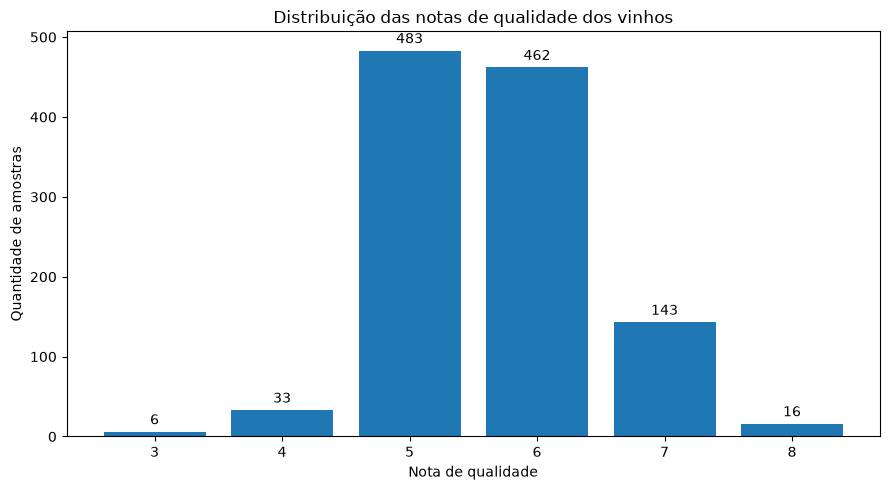

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Contagem de vinhos por nota
distribuicao = df["quality"].value_counts().sort_index()

# Percentual de cada nota
percentual = df["quality"].value_counts(
    normalize=True
).sort_index() * 100

# Tabela consolidada
tabela_qualidade = pd.DataFrame({
    "Quantidade": distribuicao,
    "Percentual (%)": percentual.round(2)
})

display(tabela_qualidade)

# Gráfico da distribuição das notas
fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    distribuicao.index.astype(str),
    distribuicao.values
)

ax.bar_label(barras, padding=3)

ax.set_title("Distribuição das notas de qualidade dos vinhos")
ax.set_xlabel("Nota de qualidade")
ax.set_ylabel("Quantidade de amostras")

plt.tight_layout()

# Exportar este gráfico, importante para o storytelling executivo
pasta_graficos = raiz / "results" / "figures"
pasta_graficos.mkdir(parents=True, exist_ok=True)
fig.savefig(pasta_graficos / "distribuicao_notas_qualidade.png", dpi=200, bbox_inches="tight")

plt.show()

### Conclusão 3 — Distribuição da qualidade dos vinhos

A análise da variável `quality` demonstrou uma concentração predominante nas notas 5 e 6, que representam conjuntamente 82,68% das 1.143 amostras. As notas extremas, especialmente 3, 4 e 8, apresentaram baixa frequência.

Considerando a classificação binária proposta no Tech Challenge, 984 amostras (86,09%) pertencem à categoria de baixa/média qualidade (nota inferior a 7), enquanto 159 amostras (13,91%) são classificadas como alta qualidade (nota igual ou superior a 7).

Essa distribuição evidencia um desbalanceamento entre as classes, que deverá ser considerado durante o treinamento e a avaliação dos modelos, evitando que a acurácia seja utilizada isoladamente como indicador de desempenho.

In [6]:

# Criar uma cópia para a análise exploratória
df_eda = df.copy()

# Transformar a qualidade em classificação binária
df_eda["quality_class"] = (
    df_eda["quality"] >= 7
).astype(int)

# Contar as amostras por classe
contagem = (
    df_eda["quality_class"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

# Montar tabela de balanceamento
balanceamento = pd.DataFrame({
    "Classe": ["Baixa/Média", "Alta"],
    "Quantidade": contagem.values,
    "Percentual (%)": (
        contagem.values / len(df_eda) * 100
    ).round(2)
})

display(balanceamento)

# Conferir se todas as observações foram classificadas
assert balanceamento["Quantidade"].sum() == len(df_eda)

print("Classificação binária criada com sucesso!")


,Classe,Quantidade,Percentual (%)
0,Baixa/Média,984,86.09
1,Alta,159,13.91


Classificação binária criada com sucesso!


**Leitura do balanceamento:** a classe 1 é minoritária. A acurácia isolada pode ser enganosa; a avaliação dos colegas deverá considerar medidas orientadas à classe positiva, sem aplicar balanceamento artificial nesta EDA.

## 1.4. Distribuição das 11 características físico-químicas

Histogramas com curvas estimadas de densidade (KDE) permitem examinar a concentração, a assimetria e caudas. O KDE é descritivo e não prova normalidade.

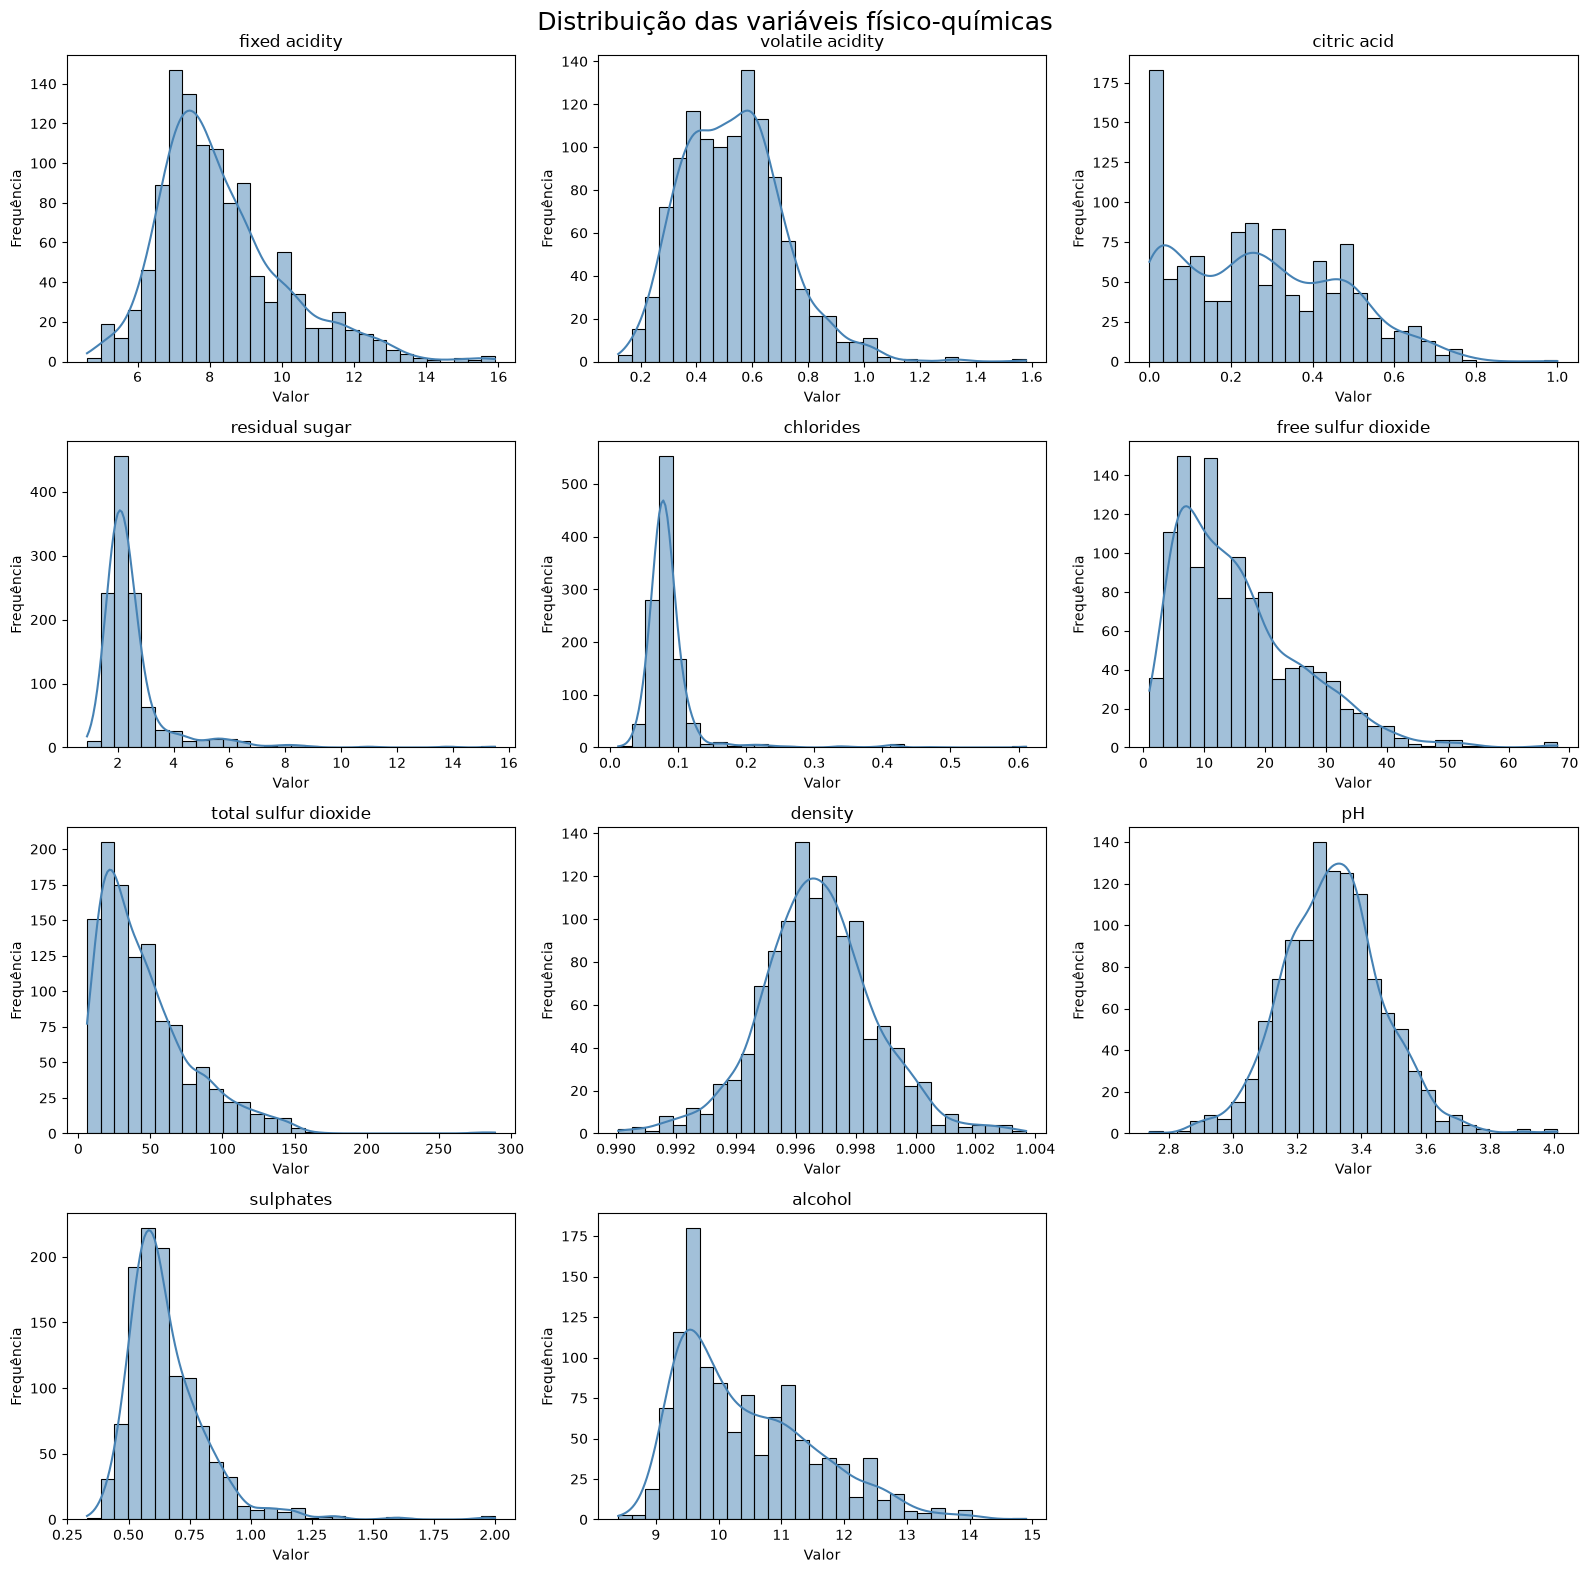

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar exclusivamente as 11 características
variaveis = df_eda.drop(
    columns=["Id", "quality", "quality_class"]
)

# Criar área com 12 espaços para 11 gráficos
fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(16, 16)
)

axes = axes.flatten()

# Criar um histograma para cada variável
for i, coluna in enumerate(variaveis.columns):

    sns.histplot(
        data=variaveis,
        x=coluna,
        bins=30,
        kde=True,
        color="steelblue",  # cor explícita para compatibilidade
        ax=axes[i]
    )

    axes[i].set_title(coluna)
    axes[i].set_xlabel("Valor")
    axes[i].set_ylabel("Frequência")

# Remover os espaços não utilizados
for i in range(len(variaveis.columns), len(axes)):
    fig.delaxes(axes[i])

fig.suptitle(
    "Distribuição das variáveis físico-químicas",
    fontsize=18
)

plt.tight_layout()

# Salvar na pasta oficial do projeto
pasta_graficos = raiz / "results" / "figures"
pasta_graficos.mkdir(parents=True, exist_ok=True)

fig.savefig(
    pasta_graficos / "distribuicoes_histogramas.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Conclusão 4 — Distribuição das variáveis físico-químicas

A análise dos histogramas das 11 características físico-químicas demonstrou comportamentos distintos entre as variáveis.

As distribuições de densidade (`density`) e pH apresentaram formatos aproximadamente simétricos, com maior concentração em torno de seus valores centrais.

Em contrapartida, variáveis como açúcar residual (`residual sugar`), cloretos (`chlorides`) e dióxido de enxofre total (`total sulfur dioxide`) apresentaram assimetria positiva acentuada, caracterizada pela concentração de observações em valores menores e pela presença de caudas prolongadas à direita.

As variáveis acidez fixa, acidez volátil, dióxido de enxofre livre, sulfatos e teor alcoólico também apresentaram diferentes graus de assimetria positiva. O ácido cítrico apresentou uma distribuição irregular, com concentração significativa de observações próximas de zero.

Esses resultados indicam a necessidade de investigar possíveis valores extremos e avaliar suas implicações para o pré-processamento. A identificação de observações incomuns não justifica sua remoção automática, sendo necessária uma análise adicional de consistência e relevância para o problema.

## 1.5. Boxplots e identificação de potenciais outliers

Os pontos além dos bigodes do boxplot indicam amostras incomuns **pela regra de 1,5 × IQR**, não erros confirmados. Primeiro visualizamos; depois quantificamos.

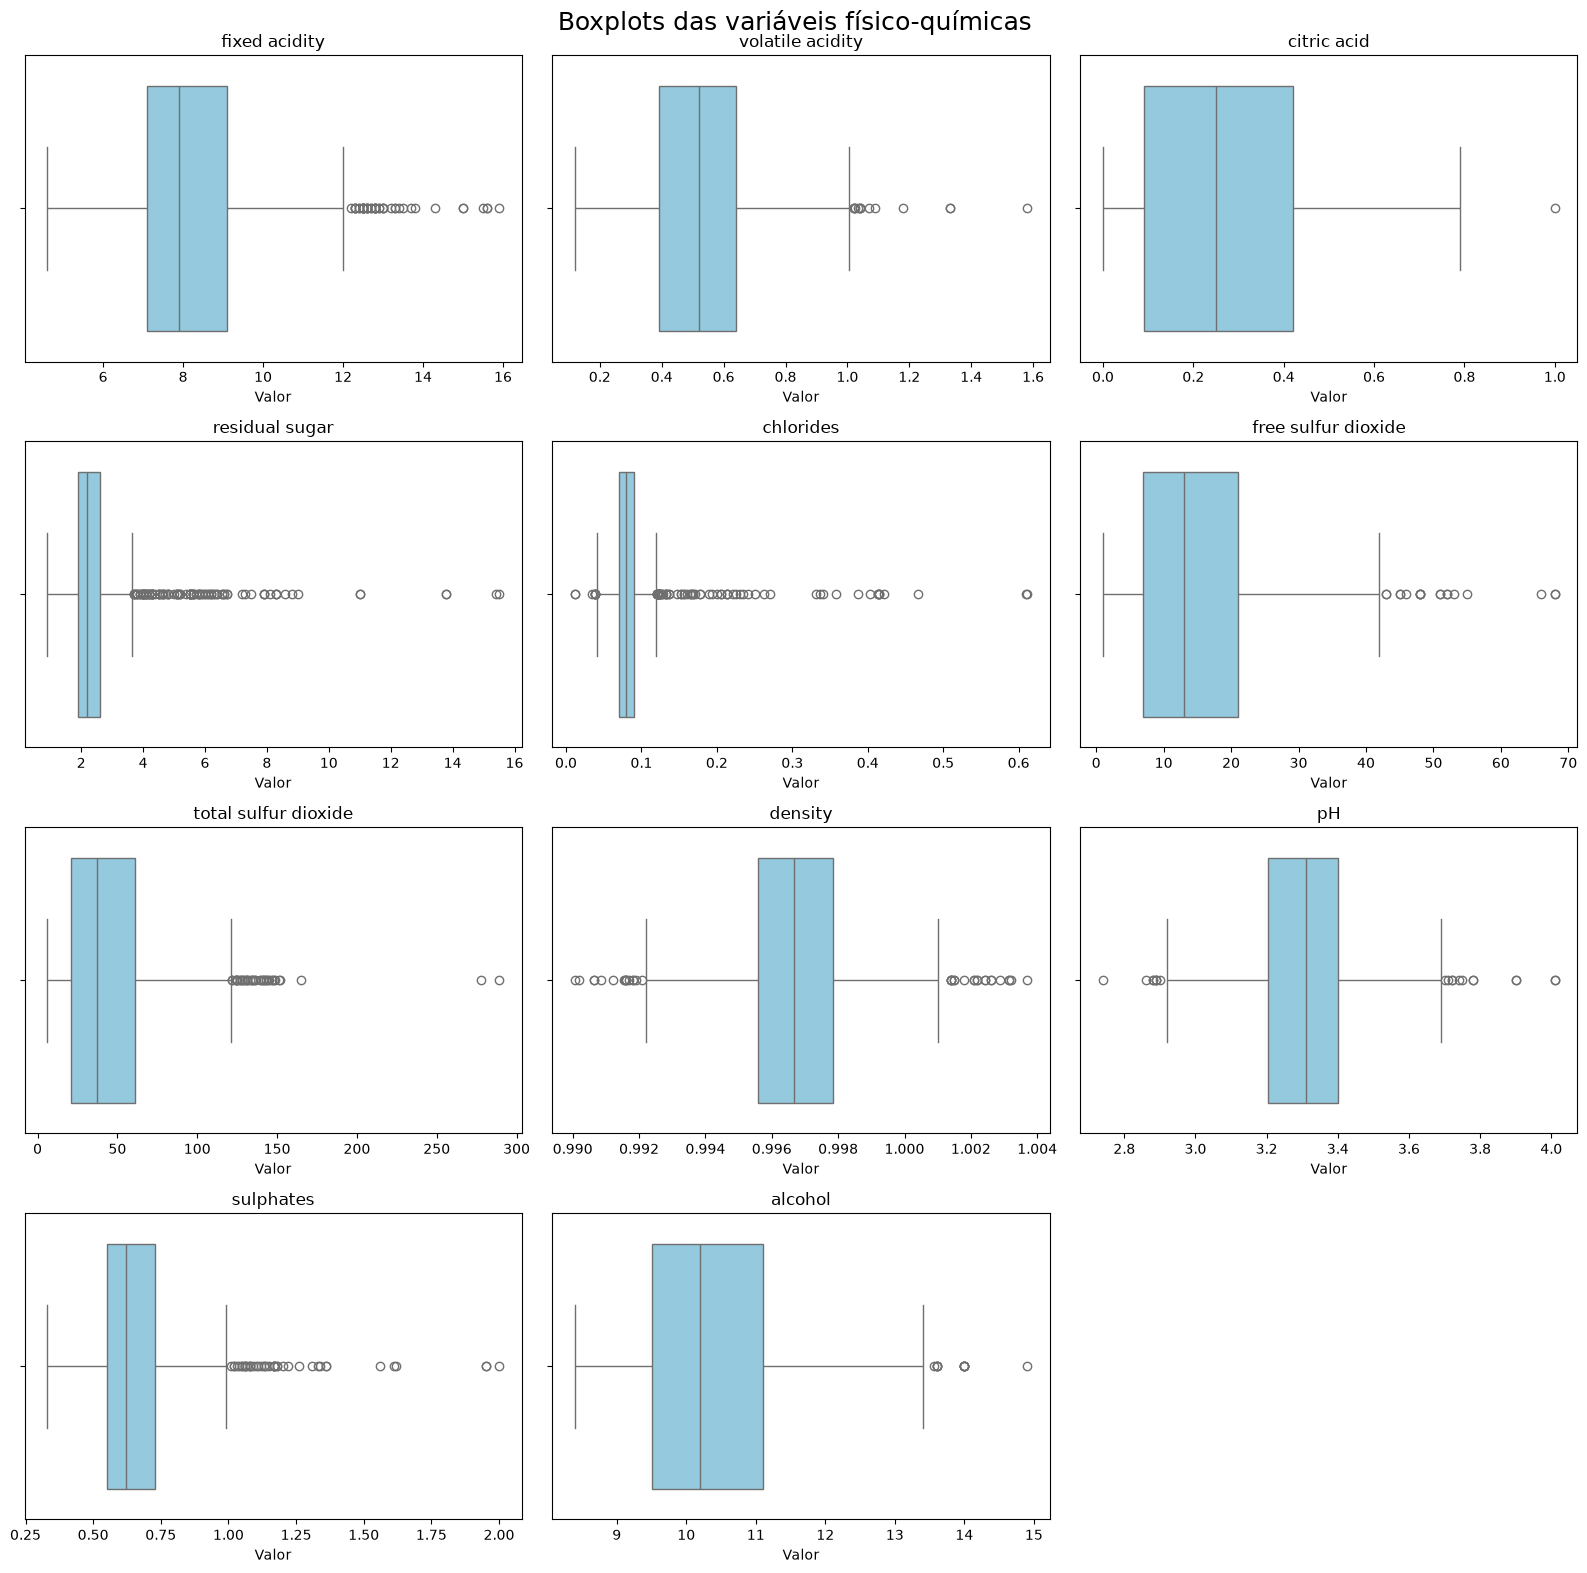

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

# Utilizar as mesmas variáveis dos histogramas
fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, coluna in enumerate(variaveis.columns):

    sns.boxplot(
        x=variaveis[coluna],
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(coluna)
    axes[i].set_xlabel("Valor")

# Remover o gráfico que não foi utilizado
for i in range(len(variaveis.columns), len(axes)):
    fig.delaxes(axes[i])

fig.suptitle(
    "Boxplots das variáveis físico-químicas",
    fontsize=18
)

plt.tight_layout()

# Salvar o gráfico
fig.savefig(
    pasta_graficos / "distribuicoes_boxplots.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


### Conclusão 5 — Análise visual de outliers

A inspeção dos boxplots evidenciou a presença de observações potencialmente atípicas em diversas características físico-químicas dos vinhos.

As variáveis `residual sugar`, `chlorides`, `total sulfur dioxide` e `sulphates` apresentaram valores elevados afastados da concentração principal dos dados. As variáveis `density` e `pH` também apresentaram observações fora dos limites em ambas as extremidades de suas distribuições.

Esses resultados são compatíveis com as assimetrias identificadas anteriormente nos histogramas.

Para quantificar as observações atípicas, será utilizado o método do Intervalo Interquartil (IQR), adotando limites de 1,5 vez o intervalo entre o primeiro e o terceiro quartis.

A identificação estatística de um outlier não implica necessariamente erro de medição. Portanto, nenhuma observação será removida sem investigação e justificativa metodológica.

### 1.5.1. Quantificação de possíveis outliers pelo IQR

Nesta etapa, utilizamos o método do Intervalo
Interquartil (IQR) para identificar observações
potencialmente atípicas nas 11 características
físico-químicas.

Os valores identificados serão investigados,
sem remoção automática de registros.

In [9]:

import pandas as pd

# Lista para armazenar os resultados
resultados_iqr = []

# Máscara para identificar outliers em cada variável
mascaras_outliers = pd.DataFrame(index=variaveis.index)

for coluna in variaveis.columns:

    # Calcular os quartis
    Q1 = variaveis[coluna].quantile(0.25)
    Q3 = variaveis[coluna].quantile(0.75)

    # Intervalo interquartil
    IQR = Q3 - Q1

    # Limites
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    # Identificar observações fora dos limites
    mascara = (
        (variaveis[coluna] < limite_inferior) |
        (variaveis[coluna] > limite_superior)
    )

    mascaras_outliers[coluna] = mascara

    quantidade = int(mascara.sum())
    percentual = quantidade / len(variaveis) * 100

    resultados_iqr.append({
        "Variável": coluna,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Qtd. outliers": quantidade,
        "Percentual (%)": percentual
    })

# Criar tabela
tabela_iqr = pd.DataFrame(resultados_iqr)

# Ordenar pelas maiores quantidades
tabela_iqr = tabela_iqr.sort_values(
    by="Qtd. outliers",
    ascending=False
)

display(tabela_iqr.round(3))

# Quantidade de amostras que possuem pelo menos
# um valor atípico em qualquer variável
linhas_atipicas = mascaras_outliers.any(axis=1).sum()

print(
    "Amostras com pelo menos um possível outlier:",
    linhas_atipicas
)

# Salvar resultados no projeto
pasta_tabelas = raiz / "results" / "tables"
pasta_tabelas.mkdir(parents=True, exist_ok=True)

tabela_iqr.to_csv(
    pasta_tabelas / "resumo_outliers_iqr.csv",
    index=False
)

print("Relatório de outliers salvo com sucesso!")


,Variável,Limite inferior,Limite superior,Qtd. outliers,Percentual (%)
3,residual sugar,0.850,3.650,110,9.624
4,chlorides,0.040,0.120,77,6.737
0,fixed acidity,4.100,12.100,44,3.850
9,sulphates,0.280,1.000,43,3.762
6,total sulfur dioxide,-39.000,121.000,40,3.500
7,density,0.992,1.001,36,3.150
8,pH,2.913,3.692,20,1.750
5,free sulfur dioxide,-14.000,42.000,18,1.575
1,volatile acidity,0.021,1.011,14,1.225
10,alcohol,7.100,13.500,12,1.050


Amostras com pelo menos um possível outlier: 295
Relatório de outliers salvo com sucesso!


### Conclusão 6 — Identificação quantitativa de outliers

A aplicação do método do Intervalo Interquartil (IQR), considerando o fator de 1,5, identificou 295 amostras (25,81% da base) com pelo menos uma característica físico-química potencialmente atípica.

As maiores concentrações ocorreram nas variáveis `residual sugar`, com 110 ocorrências (9,62%), e `chlorides`, com 77 ocorrências (6,74%). Esses resultados são compatíveis com as assimetrias observadas anteriormente nos histogramas e boxplots.

Considerando todas as variáveis, foram identificadas 415 sinalizações de outliers, distribuídas entre 295 amostras distintas.

A exclusão automática dessas observações poderia provocar perda significativa de informações e alterar a representatividade da base.

Dessa forma, optou-se por preservar os registros nesta etapa e realizar verificações adicionais de consistência físico-química antes de definir eventuais tratamentos no pré-processamento.

## 1.6. Consistência físico-química

As verificações a seguir são regras preliminares de plausibilidade (não uma validação enológica completa). Por exemplo, o limite matemático negativo do IQR para SO₂ não indica medições negativas reais.

In [10]:

import numpy as np
import pandas as pd

# Selecionar características físico-químicas
colunas_fisicas = variaveis.columns.tolist()

# Definir verificações
verificacoes = {
    "Valores negativos": (
        df_eda[colunas_fisicas] < 0
    ).any(axis=1),

    "Densidade nula ou negativa": (
        df_eda["density"] <= 0
    ),

    "pH fora de 0 a 14": (
        ~df_eda["pH"].between(0, 14)
    ),

    "SO2 livre maior que SO2 total": (
        df_eda["free sulfur dioxide"] >
        df_eda["total sulfur dioxide"]
    ),

    "Álcool fora de 0 a 100%": (
        ~df_eda["alcohol"].between(0, 100)
    ),

    "Valores não finitos": (
        ~pd.Series(
            np.isfinite(
                df_eda[colunas_fisicas].to_numpy()
            ).all(axis=1),
            index=df_eda.index
        )
    )
}

# Consolidar resultados
mascaras_inconsistencias = pd.DataFrame(verificacoes)

resumo_consistencia = pd.DataFrame({
    "Verificação": mascaras_inconsistencias.columns,
    "Ocorrências": mascaras_inconsistencias.sum().values
})

display(resumo_consistencia)

# Total de amostras com alguma inconsistência
total_inconsistentes = (
    mascaras_inconsistencias.any(axis=1).sum()
)

print(
    "Amostras com possíveis inconsistências:",
    total_inconsistentes
)

# Mostrar registros suspeitos, quando existirem
if total_inconsistentes > 0:
    display(
        df_eda.loc[
            mascaras_inconsistencias.any(axis=1)
        ].head(10)
    )


,Verificação,Ocorrências
0,Valores negativos,0
1,Densidade nula ou negativa,0
2,pH fora de 0 a 14,0
3,SO2 livre maior que SO2 total,0
4,Álcool fora de 0 a 100%,0
5,Valores não finitos,0


Amostras com possíveis inconsistências: 0


### Conclusão 7 — Verificação de consistência físico-química

A análise de consistência das 1.143 amostras não identificou ocorrências de valores negativos, densidades nulas ou negativas, valores de pH fora do intervalo de referência utilizado (0 a 14), concentrações de dióxido de enxofre livre superiores às concentrações totais, teores alcoólicos fora do intervalo de 0% a 100% ou valores numéricos não finitos.

Os resultados indicam que todas as observações atendem às regras básicas de consistência estabelecidas nesta análise.

Entretanto, a ausência dessas inconsistências não garante a inexistência de erros de medição ou de registro. As verificações representam controles preliminares de plausibilidade.

Considerando também os resultados da análise de outliers, optou-se por preservar as amostras nesta etapa, evitando exclusões automáticas que poderiam comprometer a representatividade do conjunto de dados.

Possíveis tratamentos adicionais serão avaliados na etapa de pré-processamento, conforme a necessidade dos modelos de classificação.

## 1.7. Correlações: intensidade, direção e possíveis justificativas

Usamos Pearson para identificar associações **lineares**. A correlação com `quality_class` (variável 0/1) equivale à correlação ponto-bisserial. Correlação não comprova causalidade, e variáveis com `r` próximo de zero ainda podem participar de relações não lineares.

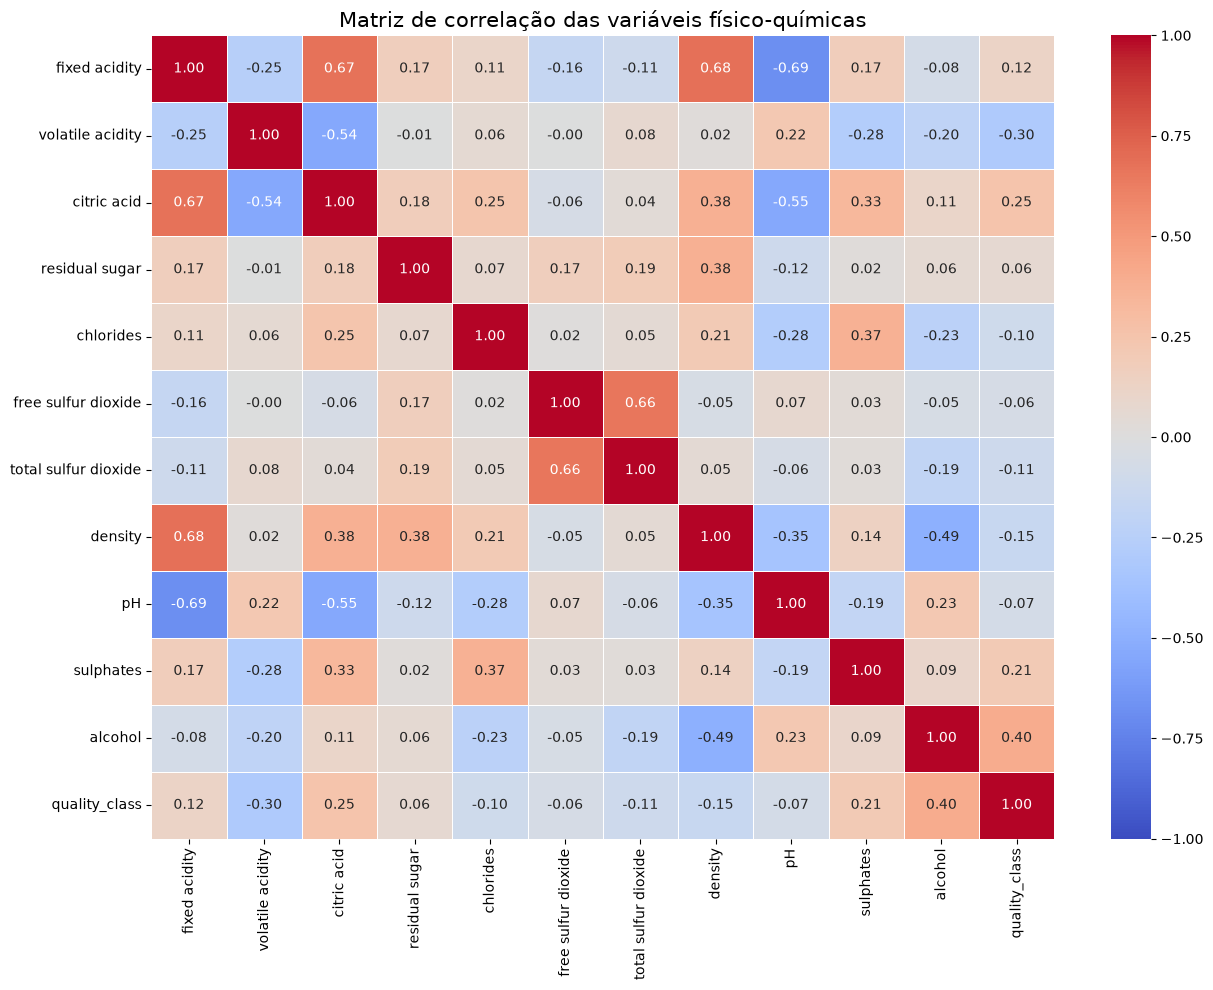

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar características e classificação binária
colunas_correlacao = list(variaveis.columns) + [
    "quality_class"
]

# Matriz de correlação de Pearson
matriz_correlacao = df_eda[
    colunas_correlacao
].corr(method="pearson")

# Criar heatmap
fig, ax = plt.subplots(figsize=(13, 10))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    "Matriz de correlação das variáveis físico-químicas",
    fontsize=15
)

plt.tight_layout()

# Salvar o gráfico
fig.savefig(
    pasta_graficos / "matriz_correlacao.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [12]:

# Correlação de cada característica com a qualidade
correlacoes_qualidade = (
    matriz_correlacao["quality_class"]
    .drop("quality_class")
    .sort_values(ascending=False)
)

display(
    correlacoes_qualidade
    .to_frame("Correlação com alta qualidade")
    .round(3)
)


,Correlação com alta qualidade
alcohol,0.404
citric acid,0.251
sulphates,0.208
fixed acidity,0.123
residual sugar,0.064
free sulfur dioxide,-0.056
pH,-0.073
chlorides,-0.104
total sulfur dioxide,-0.113
density,-0.149


### Justificativa das associações observadas

| Associação | r aproximado | Interpretação descritiva / justificativa possível |
|---|---:|---|
| Álcool × alta qualidade | +0,404 | Nesta amostra, teores mais elevados aparecem com maior frequência na classe alta; não é evidência de efeito causal. |
| Acidez volátil × alta qualidade | −0,305 | Concentrações elevadas podem estar associadas a características sensoriais indesejáveis; relação compatível com a direção observada. |
| Ácido cítrico × alta qualidade | +0,251 | Participa do perfil ácido, mas qualidade depende do equilíbrio de vários componentes. |
| Sulfatos × alta qualidade | +0,208 | Associação positiva relativamente fraca; não autoriza concluir que aumentar sulfatos elevará a qualidade. |
| Acidez fixa × pH | −0,69 | Relaciona-se ao equilíbrio ácido do vinho, embora pH e acidez fixa não sejam medidas equivalentes. |
| Acidez fixa × ácido cítrico | +0,67 | Coerente com a contribuição do ácido cítrico à composição ácida. |
| SO₂ livre × SO₂ total | +0,66 | A fração livre integra a quantidade total; associação esperada. |
| Álcool × densidade | −0,49 | A menor densidade do etanol em comparação à água ajuda a interpretar a associação. |
| Acidez fixa × densidade | +0,68 | Associação presente na amostra, possivelmente ligada à composição; mecanismo causal não foi estabelecido. |

**Limitações:** justificativas são interpretações plausíveis das medidas, não ensaios causais. A correlação pode ser influenciada por relações entre preditores, outliers e padrões não lineares. Nenhuma coluna será removida apenas com base neste heatmap.

### Conclusão 8 — Análise de correlações

A análise de correlação de Pearson identificou associações entre as características físico-químicas e a classificação binária da qualidade dos vinhos.

O teor alcoólico (`alcohol`) apresentou a maior correlação positiva com a classificação de alta qualidade (r = 0,404), seguido pelo ácido cítrico (`citric acid`, r = 0,251) e sulfatos (`sulphates`, r = 0,208).

A acidez volátil (`volatile acidity`) apresentou a correlação negativa de maior magnitude (r = −0,305), indicando que concentrações mais elevadas dessa característica estão associadas a uma menor frequência de vinhos classificados como de alta qualidade.

Também foram identificadas associações expressivas entre as próprias características físico-químicas, destacando-se acidez fixa e pH (r ≈ −0,69), acidez fixa e densidade (r ≈ +0,68), acidez fixa e ácido cítrico (r ≈ +0,67), e dióxido de enxofre livre e total (r ≈ +0,66).

Essas relações fornecem informações importantes sobre a estrutura do conjunto de dados e possíveis redundâncias entre variáveis.

Ressalta-se que correlação não implica causalidade e que associações lineares fracas não significam necessariamente ausência de valor preditivo.

Dessa forma, as 11 características físico-químicas serão preservadas nesta etapa, permitindo que sua relevância seja posteriormente avaliada durante a modelagem e validação dos classificadores.

## 1.8. Comparação das características por classe

As quatro variáveis com maiores correlações em módulo são comparadas por mediana e boxplot. A sobreposição entre grupos importa tanto quanto a diferença das medianas.

Medianas por classe de qualidade:


,alcohol,volatile acidity,citric acid,sulphates
Baixa/Média,10.0,0.55,0.24,0.60
Alta,11.6,0.36,0.41,0.74


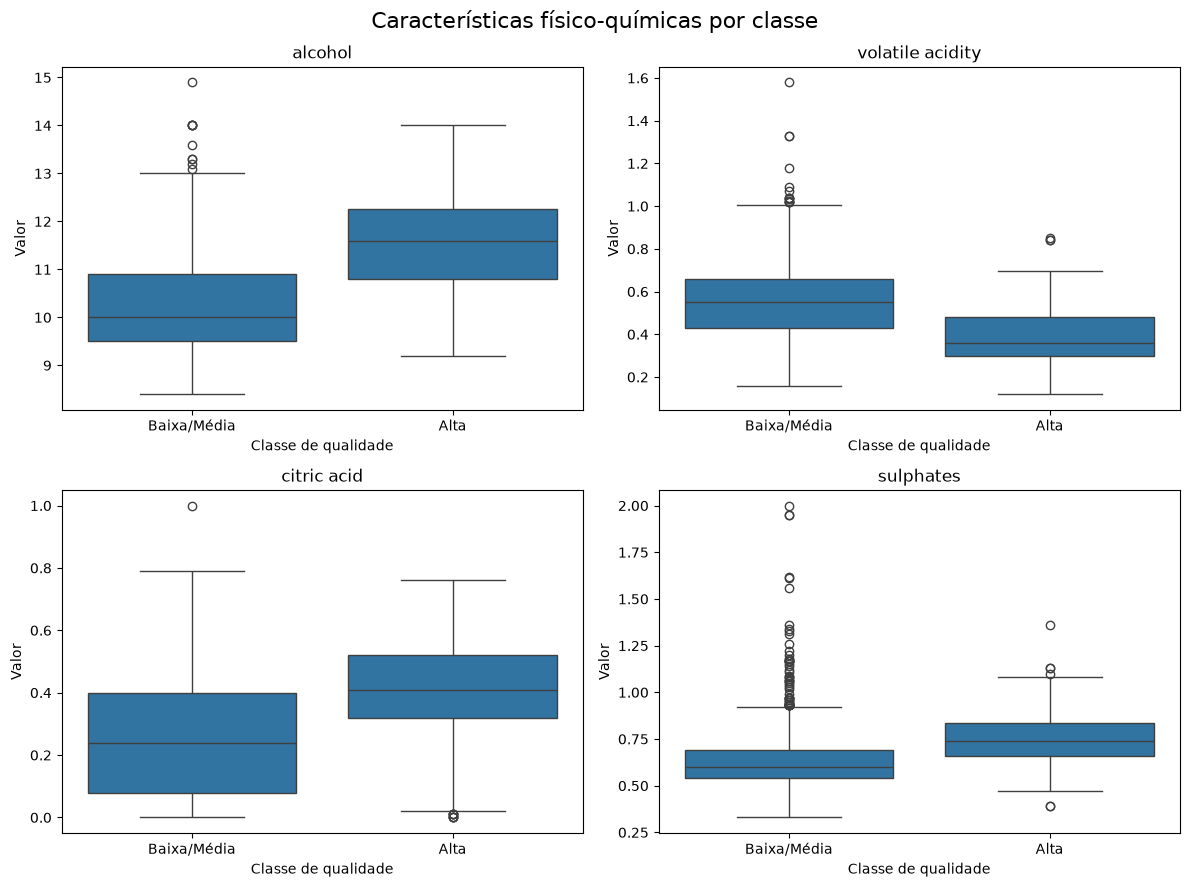

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Variáveis selecionadas com base nas correlações
variaveis_comparacao = [
    "alcohol",
    "volatile acidity",
    "citric acid",
    "sulphates"
]

# Comparar medianas das duas classes
medianas = df_eda.groupby(
    "quality_class"
)[variaveis_comparacao].median()

medianas.index = [
    "Baixa/Média",
    "Alta"
]

print("Medianas por classe de qualidade:")
display(medianas.round(3))

# Construir boxplots comparativos
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9)
)

for ax, coluna in zip(
    axes.flatten(),
    variaveis_comparacao
):
    sns.boxplot(
        data=df_eda,
        x="quality_class",
        y=coluna,
        order=[0, 1],
        ax=ax
    )

    ax.set_title(coluna)
    ax.set_xlabel("Classe de qualidade")
    ax.set_ylabel("Valor")

    ax.set_xticks(
        [0, 1],
        labels=["Baixa/Média", "Alta"]
    )

fig.suptitle(
    "Características físico-químicas por classe",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    pasta_graficos / "comparacao_por_classe.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


### Conclusão 9 — Comparação das características por classe de qualidade

A comparação das características físico-químicas entre as classes de baixa/média qualidade e alta qualidade revelou diferenças nas distribuições das quatro variáveis selecionadas com base nas maiores correlações individuais com a variável-alvo.

O teor alcoólico apresentou mediana de 11,6 nos vinhos de alta qualidade, frente a 10,0 nos vinhos de baixa/média qualidade, reforçando a associação positiva identificada anteriormente.

A acidez volátil apresentou comportamento inverso, com mediana de 0,36 nos vinhos de alta qualidade e 0,55 nos demais.

O ácido cítrico e os sulfatos também apresentaram medianas mais elevadas na classe de alta qualidade, respectivamente 0,41 e 0,74, em comparação com 0,24 e 0,60 na classe de baixa/média qualidade.

Apesar dessas diferenças, os boxplots evidenciaram sobreposição entre as distribuições, indicando que nenhuma dessas características, isoladamente, proporciona separação completa entre as classes.

Os resultados sugerem que a classificação da qualidade dos vinhos pode se beneficiar da análise conjunta das características físico-químicas por meio de algoritmos de Machine Learning.

As associações identificadas não devem ser interpretadas como relações causais.

## 1.9. Síntese da EDA e recomendações para a etapa 3

- **Base original:** 1.143 linhas e 11 características preditoras, além de `quality` e `Id`; sem valores ausentes identificados.
- **Qualidade binária:** classe 0 = 984 (86,09%); classe 1 = 159 (13,91%). Há desbalanceamento de classes.
- **Distribuições:** algumas variáveis apresentam assimetria à direita, especialmente açúcar residual, cloretos e SO₂ total; densidade e pH têm forma aproximadamente simétrica.
- **Potenciais outliers pelo IQR:** 295 amostras possuem ao menos uma variável fora dos limites; 415 sinalizações entre as 11 variáveis. Sinalização não é sinônimo de erro.
- **Integridade:** não houve violações nas seis verificações básicas de plausibilidade executadas; isso não garante perfeição de todas as medições.
- **Correlações com a classe:** álcool (+0,404), acidez volátil (−0,305), ácido cítrico (+0,251) e sulfatos (+0,208) merecem investigação na modelagem.
- **Próxima fase:** a decisão de preservar inicialmente as duplicatas é acompanhada de separação por grupos de perfis idênticos; o padronizador é ajustado **somente no treino**, no notebook `02_preprocessamento.ipynb`.

**Limitações metodológicas:** as associações não estabelecem causalidade; valores atípicos podem ser legítimos; o conjunto é desbalanceado e contém perfis repetidos. A EDA descritiva usa o conjunto completo; a **escolha de features e a validação preditiva** devem utilizar apenas dados de treinamento.